##### Install and import the libraries

In [1]:
%pip install -U ultralytics opencv-python matplotlib pandas

   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ----------------------------------- ---- 1.3/1.5 MB 8.9 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 8.6 MB/s  0:00:00
   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
   -- ------------------------------------- 2.6/48.0 MB 12.9 MB/s eta 0:00:04
   ---- ----------------------------------- 5.5/48.0 MB 12.9 MB/s eta 0:00:04
   ------- -------------------------------- 9.4/48.0 MB 14.8 MB/s eta 0:00:03
   ----------- ---------------------------- 14.2/48.0 MB 16.7 MB/s eta 0:00:03
   --------------- ------------------------ 19.1/48.0 MB 18.1 MB/s eta 0:00:02
   -------------------- ------------------- 24.9/48.0 MB 19.5 MB/s eta 0:00:02
   -------------------------- ------------- 31.2/48.0 MB 21.1 MB/s eta 0:00:01
   ----------------------------- ---------- 35.7/48.0 MB 21.0 MB/s eta 0:00:01
   ---------------------------------- ----- 41.4/48.0 MB 21.6 MB/s eta 0:00:01
   -

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


###### Set up folders and video path

In [2]:
from pathlib import Path

# Use the folder from which this notebook is running as the project folder.
PROJECT_DIR = Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Create the folders if they do not already exist.
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

VIDEO_PATH = DATA_DIR / "drone_video.mov"

# The annotated video will be saved here.
OUTPUT_VIDEO_PATH = OUTPUT_DIR / "drone_tracked.mp4"

print("Project folder:", PROJECT_DIR)
print("Video file:", VIDEO_PATH)
print("Video exists:", VIDEO_PATH.exists())
print("Output folder:", OUTPUT_DIR)

Project folder: c:\Users\anyan\source\repos\AeroTrack
Video file: c:\Users\anyan\source\repos\AeroTrack\data\drone_video.mov
Video exists: True
Output folder: c:\Users\anyan\source\repos\AeroTrack\outputs


###### Check the computer and GPU

In [3]:
import torch

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU available:", torch.cuda.get_device_name(0))
    print("CUDA version used by PyTorch:", torch.version.cuda)
else:
    DEVICE = "cpu"
    print("CUDA is not available to PyTorch. The notebook will use the CPU.")

print("Selected device:", DEVICE)

GPU available: NVIDIA GeForce RTX 3050 Ti Laptop GPU
CUDA version used by PyTorch: 13.2
Selected device: 0


###### Load a pretrained YOLO model

In [4]:
from ultralytics import YOLO

MODEL_NAME = "yolo26n.pt"

# Load the pretrained object detector.
model = YOLO(MODEL_NAME)

# Confirm the class name used for people.
print("Person class:", model.names[0])

Person class: person


###### Inspect the input video

In [5]:
import cv2

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise FileNotFoundError(
        f"Could not open video: {VIDEO_PATH}\n"
        "Check that the video is inside the data folder and that VIDEO_PATH is correct."
    )

FPS = cap.get(cv2.CAP_PROP_FPS)
FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
FRAME_WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
FRAME_HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

DURATION_SECONDS = FRAME_COUNT / FPS if FPS and FPS > 0 else 0

print(f"Resolution: {FRAME_WIDTH} x {FRAME_HEIGHT}")
print(f"FPS: {FPS:.2f}")
print(f"Frames: {FRAME_COUNT}")
print(f"Duration: {DURATION_SECONDS:.1f} seconds")

cap.release()

Resolution: 3840 x 2160
FPS: 29.97
Frames: 2272
Duration: 75.8 seconds


###### Preview person detection on one frame


People detected in this frame: 1


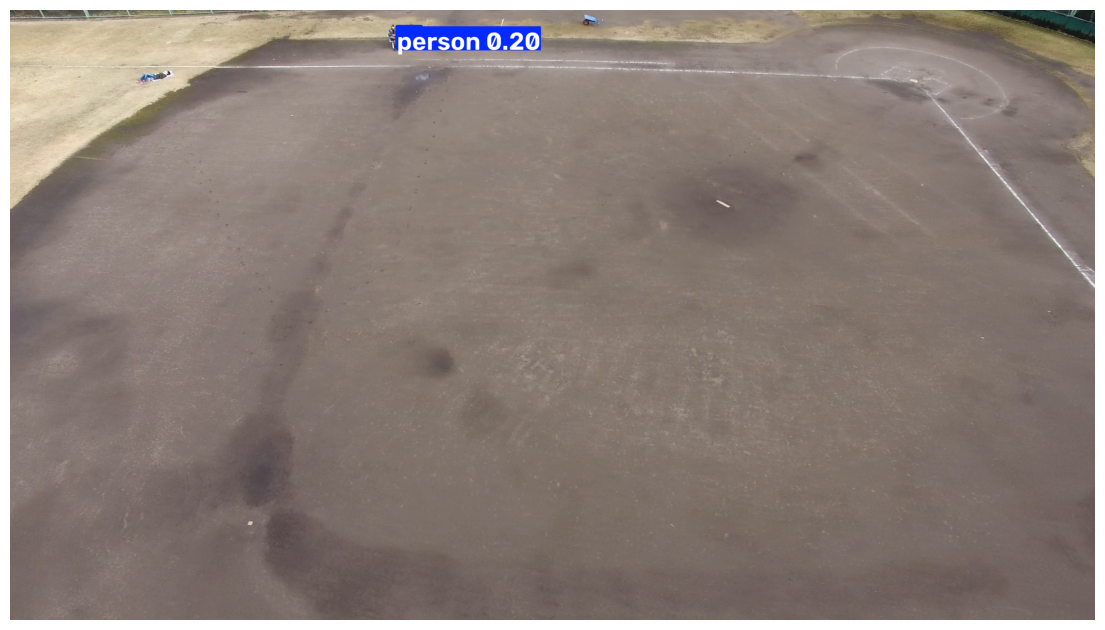

In [6]:
import cv2
import matplotlib.pyplot as plt

# Read a frame from around the middle of the original video.
cap = cv2.VideoCapture(str(VIDEO_PATH))
preview_frame_number = max(0, FRAME_COUNT // 2)
cap.set(cv2.CAP_PROP_POS_FRAMES, preview_frame_number)
success, preview_frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("Could not read a preview frame from the input video.")

# Detect only people (COCO class 0) in this frame.
preview_result = model.predict(
    preview_frame,
    classes=[0],
    conf=0.1,
    imgsz=640,
    device=DEVICE,
    verbose=False
)[0]

# Draw the detected bounding boxes and show the result.
preview_annotated = preview_result.plot()
preview_rgb = cv2.cvtColor(preview_annotated, cv2.COLOR_BGR2RGB)

print("People detected in this frame:", len(preview_result.boxes))
plt.figure(figsize=(14, 8))
plt.imshow(preview_rgb)
plt.axis("off")
plt.show()


###### Run person detection, tracking and counting

In [7]:
import cv2
from IPython.display import display, clear_output
from PIL import Image
import matplotlib.pyplot as plt
from collections import Counter
import time

# Open the video again, ready for processing.
cap = cv2.VideoCapture(str(VIDEO_PATH))

# Read video properties for the output file.
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# MP4 video writer.
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    str(OUTPUT_VIDEO_PATH),
    fourcc,
    fps if fps and fps > 0 else 25,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the output video. Check the outputs folder and video codec.")

# A set stores each tracker ID only once.
observed_track_ids = set()

# Keep a small history for the summary.
frame_number = 0
frames_with_people = 0
total_person_detections = 0

start_time = time.time()

while True:
    success, frame = cap.read()

    if not success:
        break

    frame_number += 1

    # Run YOLO detection + ByteTrack on this frame.
    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],       # COCO class 0 = person
        conf=0.1,
        imgsz=640,
        device=DEVICE,
        verbose=False
    )

    result = results[0]

    # Add detected tracking IDs to the set.
    if result.boxes is not None and len(result.boxes) > 0:
        total_person_detections += len(result.boxes)
        frames_with_people += 1

        if result.boxes.id is not None:
            frame_ids = result.boxes.id.int().cpu().tolist()
            observed_track_ids.update(frame_ids)

    # Draw boxes, class labels and tracking IDs on the frame.
    annotated_frame = result.plot()

    # Write this annotated frame to the output video.
    writer.write(annotated_frame)

    # Print progress every 100 frames.
    if frame_number % 100 == 0:
        print(
            f"Processed {frame_number}/{FRAME_COUNT} frames | "
            f"Unique tracker IDs so far: {len(observed_track_ids)}"
        )

cap.release()
writer.release()

processing_seconds = time.time() - start_time

print("\nProcessing complete.")
print("Frames processed:", frame_number)
print("Frames containing people:", frames_with_people)
print("Total person detections across frames:", total_person_detections)
print("Unique tracker IDs observed:", len(observed_track_ids))
print(f"Processing time: {processing_seconds:.1f} seconds")
print("Annotated video saved to:", OUTPUT_VIDEO_PATH)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 1.5/1.5 MB 11.7 MB/s  0:00:00

requirements: AutoUpdate success  2.8s
WARNING requirements: Restart runtime or rerun command for updates to take effect

Processed 100/2272 frames | Unique tracker IDs so far: 5
Processed 200/2272 frames | Unique tracker IDs so far: 8
Processed 300/2272 frames | Unique tracker IDs so far: 15
Processed 400/2272 frames | Unique tracker IDs so far: 28
Processed 500/2272 frames | Unique tracker IDs so far: 42
Processed 600/2272 frames | Unique tracker IDs so far: 52
Processed 700/2272 frames | Unique tracker IDs so far: 69
Processed 800/2272 frames | Unique tracker IDs so far: 83
Processed 900/2272 frames | Unique tracker IDs so far: 89
Processed 1000/2272 frames | Unique tracker IDs so far: 94
Processed 1100/2272 frames | Unique tracker IDs so far: 98
Proces

###### Display the annotated video

In [9]:
from IPython.display import Video, display

display(Video(str(OUTPUT_VIDEO_PATH), embed=False))

###### Inspect a sample frame

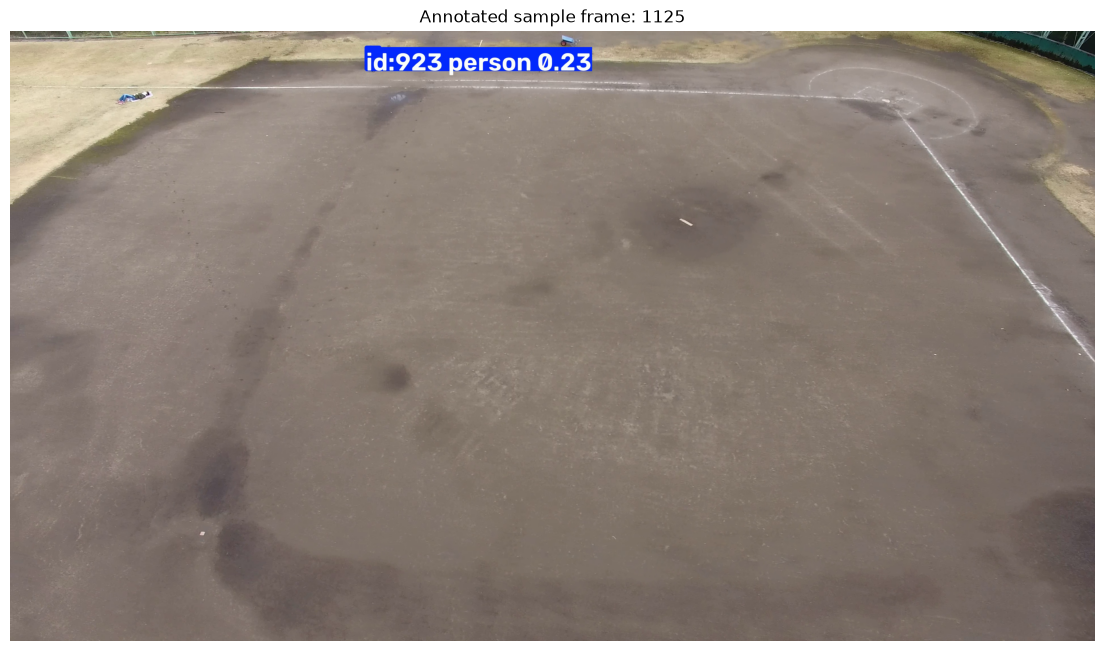

In [10]:
cap = cv2.VideoCapture(str(OUTPUT_VIDEO_PATH))

# Move to a frame around the middle of the video.
sample_frame_number = max(0, frame_number // 2)
cap.set(cv2.CAP_PROP_POS_FRAMES, sample_frame_number)

success, sample_frame = cap.read()
cap.release()

if success:
    sample_rgb = cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(14, 8))
    plt.imshow(sample_rgb)
    plt.axis("off")
    plt.title(f"Annotated sample frame: {sample_frame_number}")
    plt.show()
else:
    print("Could not read a sample frame from the output video.")

###### Save the first-run results

In [11]:
import pandas as pd

summary_df = pd.DataFrame({
    "tracker_id": sorted(observed_track_ids)
})

TRACKER_CSV_PATH = OUTPUT_DIR / "observed_tracker_ids.csv"
summary_df.to_csv(TRACKER_CSV_PATH, index=False)

print("Unique tracker IDs:", len(summary_df))
print("Tracker ID list saved to:", TRACKER_CSV_PATH)

display(summary_df.head(20))

Unique tracker IDs: 115
Tracker ID list saved to: c:\Users\anyan\source\repos\AeroTrack\outputs\observed_tracker_ids.csv


,tracker_id
0,1
1,2
2,3
3,4
4,9
5,29
6,37
7,58
8,91
9,93
